# Project 2: Income Prediction (UCI Adult dataset)
Goal: predict whether a person earns more than $50K/year. Shows data prep (hidden missing values, whitespace, categories), a sklearn pipeline, model comparison and honest evaluation.

Data: UCI Machine Learning Repository, Adult (1994 Census).

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, roc_auc_score
cols=["age","workclass","fnlwgt","education","education_num","marital_status","occupation","relationship","race","sex","capital_gain","capital_loss","hours_per_week","native_country","income"]
df=pd.read_csv("https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data",names=cols,skipinitialspace=True)
print(df.shape); df.head()

(32561, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## Data preparation
Missing values are hidden as "?". Fix that, drop duplicates and the redundant `education` column (same as `education_num`).

In [2]:
df=df.replace("?",np.nan).drop_duplicates().drop(columns=["education","fnlwgt"])
print(df.isna().sum()[lambda s:s>0])
df["income"]=(df["income"]=="<=50K").map({True:0,False:1})
print(df["income"].value_counts(normalize=True).round(3))

workclass         1836
occupation        1843
native_country     582
dtype: int64
income
0    0.759
1    0.241
Name: proportion, dtype: float64


In [3]:
X=df.drop(columns="income"); y=df["income"]
num=X.select_dtypes("number").columns; cat=X.select_dtypes("object").columns
pre=ColumnTransformer([("n",Pipeline([("i",SimpleImputer(strategy="median")),("s",StandardScaler())]),num),
                       ("c",Pipeline([("i",SimpleImputer(strategy="most_frequent")),("o",OneHotEncoder(handle_unknown="ignore"))]),cat)])
Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=0.2,stratify=y,random_state=42)

## Models

In [4]:
models={"Logistic regression":LogisticRegression(max_iter=1000),
        "Random forest":RandomForestClassifier(n_estimators=200,min_samples_leaf=3,random_state=42,n_jobs=-1)}
res={}
for n,m in models.items():
    p=Pipeline([("pre",pre),("m",m)])
    cv=cross_val_score(p,Xtr,ytr,cv=5,scoring="roc_auc").mean()
    p.fit(Xtr,ytr); res[n]=(p,cv)
    print(f"{n}: CV AUC {cv:.3f} | test AUC {roc_auc_score(yte,p.predict_proba(Xte)[:,1]):.3f}")

Logistic regression: CV AUC 0.903 | test AUC 0.909


Random forest: CV AUC 0.916 | test AUC 0.924


Best: Random forest
              precision    recall  f1-score   support

       <=50K       0.89      0.95      0.92      4940
        >50K       0.80      0.62      0.70      1568

    accuracy                           0.87      6508
   macro avg       0.84      0.79      0.81      6508
weighted avg       0.87      0.87      0.87      6508



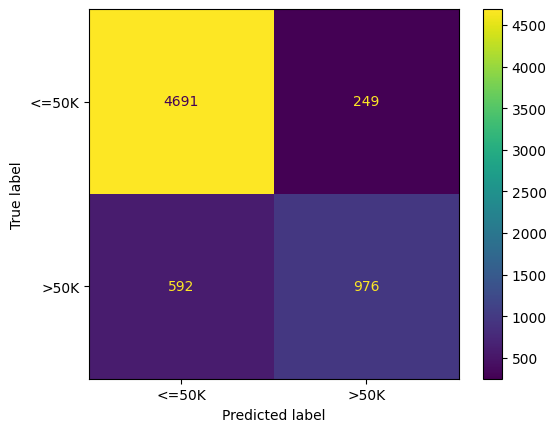

In [5]:
best=max(res,key=lambda k:res[k][1]); p=res[best][0]
print("Best:",best); print(classification_report(yte,p.predict(Xte),target_names=["<=50K",">50K"]))
ConfusionMatrixDisplay.from_estimator(p,Xte,yte,display_labels=["<=50K",">50K"]); plt.show()

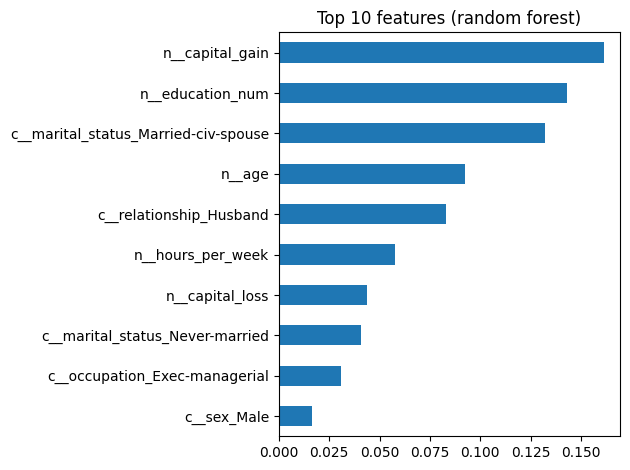

In [6]:
rf=res["Random forest"][0]
names=rf["pre"].get_feature_names_out(); imp=pd.Series(rf["m"].feature_importances_,index=names).sort_values().tail(10)
imp.plot.barh(title="Top 10 features (random forest)"); plt.tight_layout(); plt.show()

## Conclusion
Both models are compared with cross-validation on the training set only, then scored once on a held-out test set. The data is imbalanced (about 3 to 1), so AUC and per-class recall are reported, not accuracy alone. Limits: 1994 data, and the model should not be used for real decisions about people.